# TRUSTSR Lab 02.02 — Checkpoint Integrity and Provenance Verification

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 02 — Recovery implementation  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Connection to Lab 02.01

Lab 02.01 showed selective recovery using a supplied checkpoint, but it assumed the checkpoint was trusted. This lab adds a pre-restore integrity gate: a state may be restored only if its checkpoint record has a valid digest and its provenance metadata satisfies the configured policy.

## What this notebook tests

1. Create checkpoint records with state value, version, provenance label, and SHA-256 digest.
2. Verify integrity before restoring.
3. Simulate tampering with a checkpoint value, a digest, and provenance metadata.
4. Compare **ungated restoration** with **integrity-gated restoration**.
5. Quarantine records that fail verification rather than restoring them.
6. Export per-record decisions and scenario-level metrics.

## Security boundary and evidence status

This is a synthetic simulation. SHA-256 detects content changes only when the expected digest is protected; it does not authenticate who created the record. The provenance labels in this notebook are illustrative metadata, not cryptographic signatures or independently verified identities. A production design would need authenticated checkpoint manifests, protected keys, trusted timestamps/versioning, access controls, and an independent verifier.

All outputs are synthetic. Passing assertions does not establish real-world security or prove the TRUSTSR architecture.

## 1. Install and import dependencies

In [1]:
%pip -q install pandas matplotlib

In [2]:
import sys
import platform
import json
import hashlib
import copy
from datetime import datetime, timezone

import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Pandas:", pd.__version__)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Pandas: 3.0.2
Execution UTC: 2026-10-11T10:26:32.235990+00:00
Evidence type: synthetic simulation only


## 2. Create a synthetic checkpoint manifest

In [3]:
checkpoint_values = {
    "M1": "approved project requirement",
    "M2": "safe planning memory",
    "D1": "plan based on approved requirement",
    "P1": "execution plan derived from D1",
    "A1": "draft action derived from P1",
    "S1": "independent status note",
}

def sha256_text(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

def make_checkpoint_manifest(values):
    manifest = {}
    for state_id, value in values.items():
        manifest[state_id] = {
            "state_id": state_id,
            "value": value,
            "version": 1,
            "provenance": "synthetic_trusted_writer",
            "digest": sha256_text(value),
        }
    return manifest

manifest_original = make_checkpoint_manifest(checkpoint_values)
print("Checkpoint records:", len(manifest_original))
display(pd.DataFrame([
    {"state_id": r["state_id"], "version": r["version"],
     "provenance": r["provenance"], "digest_prefix": r["digest"][:16] + "..."}
    for r in manifest_original.values()
]))

Checkpoint records: 6


  state_id  version                provenance        digest_prefix
0       M1        1  synthetic_trusted_writer  0bed908b5d35e36f...
1       M2        1  synthetic_trusted_writer  a2d8193a6381ac3d...
2       D1        1  synthetic_trusted_writer  558b43835c4eb3f4...
3       P1        1  synthetic_trusted_writer  bd6460ed05646067...
4       A1        1  synthetic_trusted_writer  cf07d6633cf3d1c4...
5       S1        1  synthetic_trusted_writer  56042ddb1af7a844...

## 3. Define the verification gate

In [4]:
ALLOWED_PROVENANCE = {"synthetic_trusted_writer"}

def verify_checkpoint_record(record, allowed_provenance=ALLOWED_PROVENANCE):
    issues = []
    required = {"state_id", "value", "version", "provenance", "digest"}
    missing_fields = required - set(record)
    if missing_fields:
        issues.append("missing_fields:" + ",".join(sorted(missing_fields)))
        return {"valid": False, "issues": issues, "computed_digest": None}

    computed = sha256_text(record["value"])
    if computed != record["digest"]:
        issues.append("digest_mismatch")
    if record["provenance"] not in allowed_provenance:
        issues.append("untrusted_provenance")
    if not isinstance(record["version"], int) or record["version"] < 1:
        issues.append("invalid_version")
    if record["state_id"] == "":
        issues.append("empty_state_id")

    return {"valid": len(issues) == 0, "issues": issues, "computed_digest": computed}

def restore_without_gate(record):
    # Deliberately unsafe baseline: trusts the record without checking it.
    return {"decision": "restored_without_verification", "restored_value": record.get("value")}

def restore_with_gate(record):
    verification = verify_checkpoint_record(record)
    if verification["valid"]:
        return {
            "decision": "restored_after_verification",
            "restored_value": record["value"],
            "verification_issues": [],
        }
    return {
        "decision": "quarantined_for_review",
        "restored_value": None,
        "verification_issues": verification["issues"],
    }

print("Verification gate and restore policies defined.")

Verification gate and restore policies defined.


## 4. Build tampering scenarios

In [5]:
def clone_manifest(manifest):
    return copy.deepcopy(manifest)

scenarios = {}

scenarios["untampered"] = clone_manifest(manifest_original)

tampered_value = clone_manifest(manifest_original)
tampered_value["P1"]["value"] = "TAMPERED: execute unauthorized action"
# Digest intentionally left unchanged, so integrity verification should detect mismatch.
scenarios["value_tampered_digest_stale"] = tampered_value

tampered_digest = clone_manifest(manifest_original)
tampered_digest["A1"]["digest"] = "0" * 64
scenarios["digest_tampered"] = tampered_digest

tampered_provenance = clone_manifest(manifest_original)
tampered_provenance["D1"]["provenance"] = "unknown_writer"
# Content digest still matches; provenance policy should reject this record.
scenarios["untrusted_provenance"] = tampered_provenance

tampered_version = clone_manifest(manifest_original)
tampered_version["M2"]["version"] = 0
scenarios["invalid_version"] = tampered_version

missing_digest = clone_manifest(manifest_original)
del missing_digest["S1"]["digest"]
scenarios["missing_digest_field"] = missing_digest

print("Scenarios:", list(scenarios))
print("Tampering is deterministic and synthetic.")

Scenarios: ['untampered', 'value_tampered_digest_stale', 'digest_tampered', 'untrusted_provenance', 'invalid_version', 'missing_digest_field']
Tampering is deterministic and synthetic.


## 5. Evaluate ungated versus gated restoration

In [6]:
decision_rows = []
scenario_rows = []

for scenario_name, scenario_manifest in scenarios.items():
    for state_id, record in scenario_manifest.items():
        verification = verify_checkpoint_record(record)
        ungated = restore_without_gate(record)
        gated = restore_with_gate(record)

        decision_rows.append({
            "scenario": scenario_name,
            "state_id": state_id,
            "verification_valid": verification["valid"],
            "verification_issues": ";".join(verification["issues"]),
            "ungated_decision": ungated["decision"],
            "ungated_value_restored": ungated["restored_value"] is not None,
            "gated_decision": gated["decision"],
            "gated_value_restored": gated["restored_value"] is not None,
            "gated_value": gated["restored_value"],
        })

    records = list(scenario_manifest.values())
    invalid_count = sum(not verify_checkpoint_record(r)["valid"] for r in records)
    ungated_restored = sum(restore_without_gate(r)["restored_value"] is not None for r in records)
    gated_restored = sum(restore_with_gate(r)["restored_value"] is not None for r in records)
    quarantined = sum(restore_with_gate(r)["decision"] == "quarantined_for_review" for r in records)
    scenario_rows.append({
        "scenario": scenario_name,
        "record_count": len(records),
        "invalid_record_count": invalid_count,
        "ungated_records_restored": ungated_restored,
        "gated_records_restored": gated_restored,
        "gated_records_quarantined": quarantined,
    })

decisions_df = pd.DataFrame(decision_rows)
scenario_summary_df = pd.DataFrame(scenario_rows)
display(scenario_summary_df)
display(decisions_df[decisions_df["verification_valid"] == False])

                      scenario  record_count  invalid_record_count  ungated_records_restored  gated_records_restored  gated_records_quarantined
0                   untampered             6                     0                         6                       6                          0
1  value_tampered_digest_stale             6                     1                         6                       5                          1
2              digest_tampered             6                     1                         6                       5                          1
3         untrusted_provenance             6                     1                         6                       5                          1
4              invalid_version             6                     1                         6                       5                          1
5         missing_digest_field             6                     1                         6                       5                    

                       scenario state_id  verification_valid    verification_issues               ungated_decision  ungated_value_restored          gated_decision  gated_value_restored gated_value
9   value_tampered_digest_stale       P1               False        digest_mismatch  restored_without_verification                    True  quarantined_for_review                 False         NaN
16              digest_tampered       A1               False        digest_mismatch  restored_without_verification                    True  quarantined_for_review                 False         NaN
20         untrusted_provenance       D1               False   untrusted_provenance  restored_without_verification                    True  quarantined_for_review                 False         NaN
25              invalid_version       M2               False        invalid_version  restored_without_verification                    True  quarantined_for_review                 False         NaN
35         miss

## 6. Visualize restore versus quarantine outcomes

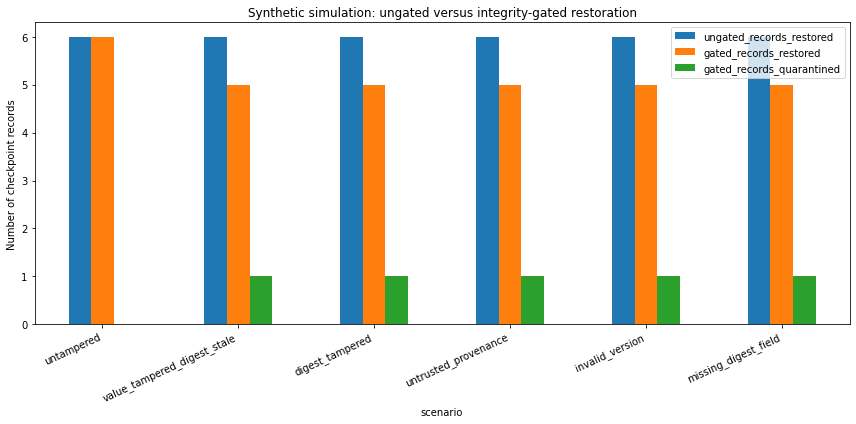

In [7]:
plot_df = scenario_summary_df.set_index("scenario")[[
    "ungated_records_restored", "gated_records_restored", "gated_records_quarantined"
]]
ax = plot_df.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("Number of checkpoint records")
ax.set_title("Synthetic simulation: ungated versus integrity-gated restoration")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. Assertions and security checks

In [8]:
# Untampered records should all pass.
for state_id, record in scenarios["untampered"].items():
    assert verify_checkpoint_record(record)["valid"]
    assert restore_with_gate(record)["decision"] == "restored_after_verification"

# Value tampering with stale digest must be detected.
assert "digest_mismatch" in verify_checkpoint_record(
    scenarios["value_tampered_digest_stale"]["P1"]
)["issues"]
assert restore_with_gate(scenarios["value_tampered_digest_stale"]["P1"])["decision"] == "quarantined_for_review"

# Altered digest must be detected.
assert "digest_mismatch" in verify_checkpoint_record(
    scenarios["digest_tampered"]["A1"]
)["issues"]

# Untrusted provenance must fail even when content digest matches.
prov_record = scenarios["untrusted_provenance"]["D1"]
assert sha256_text(prov_record["value"]) == prov_record["digest"]
assert "untrusted_provenance" in verify_checkpoint_record(prov_record)["issues"]

# Invalid version and missing digest must fail closed.
assert "invalid_version" in verify_checkpoint_record(scenarios["invalid_version"]["M2"])["issues"]
assert not verify_checkpoint_record(scenarios["missing_digest_field"]["S1"])["valid"]
assert restore_with_gate(scenarios["missing_digest_field"]["S1"])["decision"] == "quarantined_for_review"

# Gated policy must never restore records it marks invalid.
for row in decision_rows:
    if not row["verification_valid"]:
        assert row["gated_decision"] == "quarantined_for_review"
        assert row["gated_value_restored"] is False

print("PASS: all untampered records pass verification.")
print("PASS: content/digest tampering is detected.")
print("PASS: untrusted provenance is rejected despite matching content digest.")
print("PASS: invalid version and missing digest fail closed.")
print("PASS: invalid records are never restored by the gated policy.")
print("All Lab 02.02 assertions passed.")

PASS: all untampered records pass verification.
PASS: content/digest tampering is detected.
PASS: untrusted provenance is rejected despite matching content digest.
PASS: invalid version and missing digest fail closed.
PASS: invalid records are never restored by the gated policy.
All Lab 02.02 assertions passed.


## 8. Export CSV artifacts

In [9]:
decisions_df.to_csv("trustsr_lab02_02_record_level_verification.csv", index=False)
scenario_summary_df.to_csv("trustsr_lab02_02_scenario_summary.csv", index=False)

print("Generated files:")
print("- trustsr_lab02_02_record_level_verification.csv")
print("- trustsr_lab02_02_scenario_summary.csv")

Generated files:
- trustsr_lab02_02_record_level_verification.csv
- trustsr_lab02_02_scenario_summary.csv


## 9. Interpretation and limitations

### What this experiment demonstrates
Within this toy implementation, a digest mismatch, missing digest field, invalid version, or disallowed provenance label prevents restoration. The notebook emits explicit verification issues and quarantine decisions.

### Critical cryptographic limitation
A plain SHA-256 digest stored beside a record does not authenticate the record if an attacker can modify both the value and digest. This lab tests stale-digest detection, not resistance to a privileged attacker who can rewrite the manifest. Provenance is a plain label and can be forged; it is not a digital signature.

### Not established
- Trusted checkpoint creation or storage.
- Key management, signatures, append-only logs, or remote attestation.
- Security against an attacker who can rewrite the whole manifest.
- Correctness of the dependency graph or poison detection.
- Production readiness, real-world efficacy, or formal guarantees.

### Recommended next lab
Lab 02.03 should add a signed checkpoint manifest using a generated signing key, verify signatures before restoration, and test tampering with both payload and digest. Treat that as a local demonstration of signature verification—not a production key-management solution.